# AS4 Q-Learning Training, Evaluation, and Report Evidence

This notebook is the experiment controller for the AS4 Godot 2D Platform Collector. Python launches the Godot project through `AS4GodotEnv`, exchanges JSON reset/step messages over local WebSocket port `8765`, trains **tabular Q-learning** agents sequentially, evaluates saved Q-tables, and exports report-ready CSV files and figures.

This is a converted version of the original PPO notebook. Because Q-learning of the classic tabular kind needs a *discrete* state space, and `AS4GodotEnv` exposes twelve continuous observations, the biggest structural change from the PPO notebook is a discretization step that turns each continuous observation into a small integer grid cell before it is used as a Q-table key. Everything downstream (evaluation, plotting, checkpoint screening, multi-seed validation) mirrors the original PPO notebook's structure so the two experiments stay directly comparable.

### Execution order and purpose

1. **Set up reproducibility and paths** so every run uses known software, seeds, folders, and queue controls.
2. **Define the state discretization** used to turn continuous observations into Q-table keys.
3. **Validate the Gymnasium–Godot boundary** before spending time on training.
4. **Measure a random-agent control** to establish the untrained performance floor.
5. **Resolve seven controlled Q-learning configurations** from one baseline plus one-parameter alternatives.
6. **Train sequentially** because all environments share WebSocket port `8765`.
7. **Screen checkpoints** and retain the strongest checkpoint for each configuration.
8. **Evaluate greedy and epsilon-greedy policies** with a common episode budget.
9. **Generate tables and plots** for comparison, diagnosis, and the assignment report.
10. **Repeat training across additional seeds** to estimate sensitivity to initialization.

When `SKIP_COMPLETED_MODELS` is enabled, existing final Q-table files are reused. This supports recovery after an interrupted long run, but those files must belong to the same observation space, discretization, reward design, and experiment version.

## 1. Environment and reinforcement-learning formulation

The environment logic is implemented across `main.gd`, `player.gd`, `apple.gd`, `snail.gd`, and `websocket_bridge.gd`; `as4_env.py` exposes that game as a Gymnasium environment. `as4_env.py` itself is algorithm-agnostic and is unchanged from the PPO version of this project.

### Observation space: 12 normalized values

| Index | Observation | Purpose |
|---:|---|---|
| 0–1 | Player x/y position | Locates the agent within the level. |
| 2–3 | Horizontal/vertical velocity | Represents current motion and jump phase. |
| 4 | On-floor flag | Indicates whether a jump can begin. |
| 5 | Touching-wall flag | Helps distinguish blocked movement. |
| 6 | Horizontal wall normal | Identifies which side is obstructed. |
| 7–8 | Relative x/y position of the active navigation target | Directs the policy toward the next reachable objective. |
| 9–10 | Relative x/y position of the nearest active snail | Supports enemy avoidance. |
| 11 | Fraction of apples remaining | Represents task progress. |

The active navigation target is normally the nearest apple. After the lower apple is collected, `main.gd` temporarily exposes a central-platform approach waypoint so both the observation and distance shaping describe a reachable route around the wall.

### Discrete action space

| Value | Action | Purpose |
|---:|---|---|
| 0 | Do nothing | Allows waiting or preserving a trajectory. |
| 1 | Move left | Horizontal control. |
| 2 | Move right | Horizontal control. |
| 3 | Jump | Vertical control without horizontal input. |
| 4 | Move left and jump | Combined platforming action. |
| 5 | Move right and jump | Combined platforming action. |

### Reward and termination design

| Event | Reward | Purpose |
|---|---:|---|
| Each decision step | −0.01 | Discourages unnecessarily long episodes. |
| Reach the upper-apple waypoint once | +4 | Rewards the required detour. |
| Collect an apple | +5 | Rewards partial task progress. |
| Collect all apples | +20 | Rewards successful completion and terminates the episode. |
| Hit an enemy | −10 | Penalizes unsafe movement and terminates the episode. |
| Fall below the level | −10 | Penalizes falling and terminates the episode. |
| Reach 1,000 decisions | −8 | Ends the episode as a Gymnasium truncation. |
| Move toward/away from the active target | Clipped to [−0.1, +0.1] | Supplies dense progress feedback without overwhelming event rewards. |

`websocket_bridge.gd` pauses the scene between requests. One Python action is held for four Godot physics ticks, so movement, collisions, rewards, and the returned transition stay synchronized.

### State discretization for tabular Q-learning

Tabular Q-learning keeps one row of action-values per *discrete* state, so the twelve continuous observations above are each cut into a small number of equal-width bins before being used as a Q-table key. Binary flags (on-floor, touching-wall) get exactly two bins so no information is lost; position, velocity, and relative-distance observations get coarser bins because the table would otherwise never revisit the same state twice. `BINS_PER_DIMENSION` (Section 2.2) fixes this grid, and it is held constant across every configuration so configurations differ only in their learning hyperparameters, mirroring how the PPO notebook kept the network architecture constant across its seven configurations.

## 2. Setup and reproducibility

The next cell imports the numerical, plotting, Gymnasium, and WebSocket libraries used throughout the notebook, plus Python's standard `pickle`/`csv`/`json` modules used to save Q-tables and write training logs in the same CSV format the plotting cells expect. It seeds Python's and NumPy's random number generators with `SEED = 123`. Tabular Q-learning has no neural network, so PyTorch and Stable-Baselines3's `PPO` are no longer needed; `stable_baselines3.common.env_checker.check_env` is kept because it validates the Gymnasium interface itself, independent of which algorithm is used.

In [47]:
import csv
import json
import pickle
import platform
import random
import shutil
import sys
import time
from pathlib import Path

import gymnasium
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import websockets
from stable_baselines3.common.env_checker import check_env

SEED = 123
random.seed(SEED)
np.random.seed(SEED)

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Platform:", platform.platform())
print("Gymnasium:", gymnasium.__version__)
print("WebSockets:", websockets.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)

Python executable: d:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\.conda\python.exe
Python version: 3.14.7 | packaged by Anaconda, Inc. | (main, Aug 14 2026, 10:12:46) [MSC v.1942 64 bit (AMD64)]
Platform: Windows-11-10.0.26200-SP0
Gymnasium: 1.3.0
WebSockets: 17.0.1
NumPy: 2.5.2
Pandas: 3.0.5
Matplotlib: 3.11.1


### 2.1 Project paths and execution controls

The next cell searches upward from the current working directory for `project.godot`, creates canonical `results/` and `models/` folders, and adds `agent/` to Python's import path before importing `AS4GodotEnv`.

The control variables separate quick checks from expensive work:

- `HEADLESS` controls rendering; headless mode is intended for faster training.
- `TRAIN_EXPERIMENTS` enables or disables the main training queue.
- `SKIP_COMPLETED_MODELS` supports resuming from existing final Q-table files.
- `SMOKE_TEST_TIMESTEPS` and `TARGET_TOTAL_TIMESTEPS` define the short preflight stage and full per-model budget, counted in environment steps rather than PPO rollout timesteps, but otherwise serving the same purpose.
- Episode counts define random, checkpoint-screening, and final-evaluation sample sizes.
- `EXPERIMENT_NAMES_TO_RUN` selects all seven active configurations.

`CONFIG_DIRECTORY` is kept only for parity with the PPO notebook's unused `ppo_configs/` path; active configurations are defined directly in code and do not use that directory.

In [48]:
# Locate the repository from the notebook directory or any parent directory.
search_locations = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
AS4_DIRECTORY = next(
    (
        location
        for location in search_locations
        if (location / "project.godot").exists()
    ),
    None,
)
if AS4_DIRECTORY is None:
    raise FileNotFoundError(
        "Could not locate the AS4 Godot project (project.godot) from the current directory"
    )

AGENT_DIRECTORY = AS4_DIRECTORY / "agent"
CONFIG_DIRECTORY = AGENT_DIRECTORY / "q_configs"
RESULTS_DIRECTORY = AS4_DIRECTORY / "results"
MODELS_DIRECTORY = AS4_DIRECTORY / "models"
RESULTS_DIRECTORY.mkdir(parents=True, exist_ok=True)
MODELS_DIRECTORY.mkdir(parents=True, exist_ok=True)

if str(AGENT_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(AGENT_DIRECTORY))

from as4_env import AS4GodotEnv

# Queue controls. Review these values before starting a long run.
#
# HEADLESS = True skips rendering entirely and, combined with the
# "--fixed-fps" flag already set inside as4_env.py, lets Godot's physics run
# much faster than real time - this also matters more now that several
# Godot instances render at once during parallel training. Only switch this
# to False temporarily when you want to visually watch the agent play (e.g.
# for a report screenshot/video), and prefer doing that with a single config
# rather than the full parallel queue.
HEADLESS = False
TRAIN_EXPERIMENTS = True
# Set to True only if you already have completed models for some configs
# (e.g. from an earlier partial run) and want to skip retraining them.
SKIP_COMPLETED_MODELS = True
SMOKE_TEST_TIMESTEPS = 5_000
TARGET_TOTAL_TIMESTEPS = 500_000
RANDOM_BASELINE_EPISODES = 50
# Run every configuration defined in Section 6.
EXPERIMENT_NAMES_TO_RUN = {
    "baseline",
    "low_alpha",
    "high_alpha",
    "high_exploration",
    "very_high_exploration",
    "fast_epsilon_decay",
    "high_gamma",
}
CHECKPOINT_FREQUENCY = 50_000
CHECKPOINT_SCREEN_EPISODES = 5
FINAL_EVALUATION_EPISODES = 50
# Fixed epsilon used only for "stochastic" (exploratory) evaluation episodes,
# analogous to sampling from PPO's action probability distribution instead
# of taking its highest-probability action.
EVAL_STOCHASTIC_EPSILON = 0.10

print("AS4 project directory:", AS4_DIRECTORY)
print("Configuration directory:", CONFIG_DIRECTORY)
print("Results directory:", RESULTS_DIRECTORY)
print("Models directory:", MODELS_DIRECTORY)
print("AS4GodotEnv imported successfully")

AS4 project directory: D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4
Configuration directory: D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\agent\q_configs
Results directory: D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\results
Models directory: D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\models
AS4GodotEnv imported successfully


### 2.2 State discretization

`BINS_PER_DIMENSION` fixes how many equal-width bins each of the twelve observations is cut into. The two boolean flags (on-floor, touching-wall) get exactly two bins; position and relative-distance observations get more bins because they carry more task-relevant information; velocities and the wall-normal get fewer bins because coarse motion buckets are enough to distinguish "rising" from "falling" or "pushing left" from "pushing right". `STATE_SPACE_SIZE` is the theoretical number of distinct grid cells; the Q-table itself only ever allocates rows for states the agent actually visits, so this number is an upper bound, not the memory footprint.

In [49]:
# One bin count per observation, in the same order as the table in Section 1.
BINS_PER_DIMENSION = np.array([4, 4, 3, 3, 2, 2, 3, 4, 4, 4, 4, 3])

STATE_SPACE_SIZE = int(np.prod(BINS_PER_DIMENSION))
print("Bins per dimension:", BINS_PER_DIMENSION.tolist())
print(f"Theoretical state space size: {STATE_SPACE_SIZE:,} grid cells (upper bound; Q-table stores only visited states)")


def discretize_observation(observation, low, high, bins_per_dimension):
    """Map a continuous observation into a tuple of bin indices.

    The tuple is hashable, so it can be used directly as a Q-table key.
    """
    ratios = (np.asarray(observation, dtype=np.float64) - low) / (high - low)
    ratios = np.clip(ratios, 0.0, 0.999999)
    indices = (ratios * bins_per_dimension).astype(int)
    return tuple(int(i) for i in indices)

Bins per dimension: [4, 4, 3, 3, 2, 2, 3, 4, 4, 4, 4, 3]
Theoretical state space size: 1,327,104 grid cells (upper bound; Q-table stores only visited states)


In [50]:
for monitor_path in RESULTS_DIRECTORY.glob("*_monitor.csv"):
    with open(monitor_path, "r") as f:
        lines = f.readlines()
 
    if lines and not lines[0].startswith("#"):
        lines[0] = "#" + lines[0]
        with open(monitor_path, "w") as f:
            f.writelines(lines)
        print(f"Patched: {monitor_path.name}")
    else:
        print(f"Already OK: {monitor_path.name}")

Already OK: baseline_monitor.csv
Already OK: baseline_seed203_monitor.csv
Already OK: baseline_seed521_monitor.csv
Already OK: baseline_seed848_monitor.csv
Already OK: fast_epsilon_decay_monitor.csv
Already OK: fast_epsilon_decay_seed203_monitor.csv
Already OK: fast_epsilon_decay_seed521_monitor.csv
Already OK: fast_epsilon_decay_seed848_monitor.csv
Already OK: high_alpha_monitor.csv
Already OK: high_alpha_seed203_monitor.csv
Already OK: high_alpha_seed521_monitor.csv
Already OK: high_alpha_seed848_monitor.csv
Already OK: high_exploration_monitor.csv
Already OK: high_exploration_seed203_monitor.csv
Already OK: high_exploration_seed521_monitor.csv
Already OK: high_exploration_seed848_monitor.csv
Already OK: high_gamma_monitor.csv
Already OK: high_gamma_seed203_monitor.csv
Already OK: high_gamma_seed521_monitor.csv
Already OK: high_gamma_seed848_monitor.csv
Already OK: low_alpha_monitor.csv
Already OK: low_alpha_seed203_monitor.csv
Already OK: low_alpha_seed521_monitor.csv
Already OK: lo

## 3. Reusable evaluation and plotting functions

The next cell centralizes operations that must remain consistent across policies:

- `run_episodes` executes complete random or Q-learning episodes, records episode metrics, and optionally retains every visited player position. It is unchanged from the PPO notebook because it only relies on a `model.predict(observation, deterministic=...)` interface, and `QLearningAgent` (Section 4) implements exactly that interface.
- `summarize_results` converts episode records into report metrics: mean reward, reward variability, episode length, apples, and completion rate.
- `save_figure` applies a consistent layout, saves a 300-DPI image under `results/`, and displays it in the notebook.

Reusing these functions prevents the random baseline and trained policies from being measured with different logic.

In [51]:
def run_episodes(
    env,
    episodes,
    *,
    model=None,
    seed=SEED,
    deterministic=True,
):
    """Evaluate a random policy (model=None) or a supplied model for a fixed
    number of complete episodes.

    Returns two DataFrames:
    - results_df: one row per episode (reward, steps, terminal reason, etc.)
    - positions_df: one row per environment step with the player's (x, y)
      position, tagged by episode number. Used for trajectory/heatmap plots.
    """
    records = []
    positions = []
    observation, info = env.reset(seed=seed)

    for episode in range(1, episodes + 1):
        episode_reward = 0.0
        episode_steps = 0
        terminated = False
        truncated = False

        # Record the player's starting position for this episode.
        positions.append(
            {"episode": episode, "x": info.get("player_x"), "y": info.get("player_y")}
        )

        while not (terminated or truncated):
            if model is None:
                action = env.action_space.sample()
            else:
                action, _state = model.predict(
                    observation,
                    deterministic=deterministic,
                )

            observation, reward, terminated, truncated, info = env.step(action)
            episode_reward += reward
            episode_steps += 1

            # Record the position after every step, not just at episode end,
            # so the trajectory/heatmap plot shows the whole path taken.
            positions.append(
                {"episode": episode, "x": info["player_x"], "y": info["player_y"]}
            )

        records.append(
            {
                "episode": episode,
                "reward": episode_reward,
                "steps": episode_steps,
                "reason": info.get("reason", "unknown"),
                "apples_collected": info.get("apples_collected", 0),
                "completed": info.get("reason") == "success",
            }
        )

        if episode < episodes:
            observation, info = env.reset()

    return pd.DataFrame(records), pd.DataFrame(positions)


def summarize_results(results_df):
    # Return report-ready aggregate metrics for one policy.
    return {
        "episodes": len(results_df),
        "mean_reward": results_df["reward"].mean(),
        "reward_std": results_df["reward"].std(),
        "mean_steps": results_df["steps"].mean(),
        "mean_apples": results_df["apples_collected"].mean(),
        "completion_rate": results_df["completed"].mean(),
    }


def save_figure(filename):
    # Save the currently active matplotlib figure at report quality (300 DPI)
    # into RESULTS_DIRECTORY, then display it inline. Every plotting cell in
    # this notebook calls this at the end instead of plt.show() directly, so
    # every figure used as report evidence is also saved to disk automatically.
    plt.tight_layout()
    plt.savefig(RESULTS_DIRECTORY / filename, dpi=300, bbox_inches="tight")
    plt.show()

## 4. The `QLearningAgent`

The next cell defines the tabular Q-learning agent itself. It deliberately mirrors the parts of Stable-Baselines3's `PPO` interface that the rest of the notebook depends on:

- `predict(observation, deterministic=True)` returns `(action, state)` just like `model.predict(...)`, so `run_episodes` above needs no changes. `deterministic=True` takes the highest-value action for the observation's discretized state (greedy/argmax); `deterministic=False` acts epsilon-greedily using `EVAL_STOCHASTIC_EPSILON`, which plays the same role as sampling from PPO's action-probability distribution.
- `save(path)` / `QLearningAgent.load(path)` serialize the Q-table and its hyperparameters to a pickle file, replacing PPO's `.zip` checkpoints.
- `num_timesteps` counts total environment steps taken during training, replacing PPO's identically-named attribute so training-loop and metadata code can stay structurally the same.

`update(...)` implements the standard tabular Q-learning rule: `Q(s, a) <- Q(s, a) + alpha * (reward + gamma * max_a' Q(s', a') - Q(s, a))`, using `0` instead of the bootstrapped next-state value when the transition is terminal. States are created lazily (a state's row is all zeros — "optimistic-neutral" — until first visited), which is why the Q-table only ever grows to the number of states actually visited rather than the full `STATE_SPACE_SIZE`.

In [52]:
class QLearningAgent:
    """Tabular Q-learning agent over a discretized version of AS4GodotEnv's
    observation space.
    """

    def __init__(
        self,
        *,
        bins_per_dimension,
        low,
        high,
        n_actions,
        alpha=0.1,
        gamma=0.99,
        epsilon_start=1.0,
        epsilon_min=0.05,
        epsilon_decay=0.9995,
        seed=None,
    ):
        self.bins_per_dimension = np.asarray(bins_per_dimension)
        self.low = np.asarray(low, dtype=np.float64)
        self.high = np.asarray(high, dtype=np.float64)
        self.n_actions = n_actions
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon_start = epsilon_start
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.epsilon_current = epsilon_start

        self.q_table = {}
        self.num_timesteps = 0
        self.rng = np.random.default_rng(seed)

    def _discretize(self, observation):
       return discretize_observation(
           observation, self.low, self.high, self.bins_per_dimension
       )

    def _row(self, state):
        row = self.q_table.get(state)
        if row is None:
            row = np.zeros(self.n_actions, dtype=np.float32)
            self.q_table[state] = row
        return row

    def predict(self, observation, deterministic=True):
        """Match Stable-Baselines3's model.predict(obs, deterministic) so
        run_episodes needs no changes for this agent type.
        """
        state = self._discretize(observation)
        row = self.q_table.get(state)

        if row is None:
            # Never-visited state: no learned preference, so act uniformly
            # at random rather than defaulting to action 0 every time.
            return int(self.rng.integers(self.n_actions)), None

        if deterministic:
            action = int(np.argmax(row))
        else:
            if self.rng.random() < EVAL_STOCHASTIC_EPSILON:
                action = int(self.rng.integers(self.n_actions))
            else:
                action = int(np.argmax(row))
        return action, None

    def act_epsilon_greedy(self, observation, epsilon):
        """Action selection used during training (not evaluation)."""
        if self.rng.random() < epsilon:
            return int(self.rng.integers(self.n_actions))
        state = self._discretize(observation)
        row = self.q_table.get(state)
        if row is None:
            return int(self.rng.integers(self.n_actions))
        return int(np.argmax(row))

   
    def update(self,observation,action,reward,next_observation,terminated,truncated,):
        state = self._discretize(observation)
        row = self._row(state)

        if terminated:
            target = reward
        else:
            next_state = self._discretize(next_observation)
            next_row = self._row(next_state)
            target = reward + self.gamma * float(np.max(next_row))

        row[action] += self.alpha * (target - row[action])


    def decay_epsilon(self):
        self.epsilon_current = max(
            self.epsilon_min, self.epsilon_current * self.epsilon_decay
        )

    def save(self, path):
        path = Path(path).with_suffix(".pkl")
        payload = {
            "bins_per_dimension": self.bins_per_dimension,
            "low": self.low,
            "high": self.high,
            "n_actions": self.n_actions,
            "alpha": self.alpha,
            "gamma": self.gamma,
            "epsilon_start": self.epsilon_start,
            "epsilon_min": self.epsilon_min,
            "epsilon_decay": self.epsilon_decay,
            "epsilon_current": self.epsilon_current,
            "num_timesteps": self.num_timesteps,
            "q_table": self.q_table,
        }
        with open(path, "wb") as file:
            pickle.dump(payload, file)

    @classmethod
    def load(cls, path):
        path = Path(path).with_suffix(".pkl")
        with open(path, "rb") as file:
            payload = pickle.load(file)

        agent = cls(
            bins_per_dimension=payload["bins_per_dimension"],
            low=payload["low"],
            high=payload["high"],
            n_actions=payload["n_actions"],
            alpha=payload["alpha"],
            gamma=payload["gamma"],
            epsilon_start=payload["epsilon_start"],
            epsilon_min=payload["epsilon_min"],
            epsilon_decay=payload["epsilon_decay"],
        )
        agent.epsilon_current = payload["epsilon_current"]
        agent.num_timesteps = payload["num_timesteps"]
        agent.q_table = payload["q_table"]
        return agent


class QLearningMonitor:
    """Writes one row per completed episode in the same CSV shape as
    Stable-Baselines3's Monitor wrapper (a leading '#' comment line, then
    columns r/l/t plus any requested info keys), so the existing training-
    curve plotting cell (Section 10.1) can read either notebook's logs
    unchanged.
    """

    def __init__(
        self,
        path,
        info_keywords=(
            "reason",
            "apples_collected",
            "total_reward"
        )
    ):
        self.path = Path(path)
        self.info_keywords = tuple(info_keywords)
        self.t_start = time.time()

        self._file = open(
            self.path,
            "w",
            newline=""
        )

        # IMPORTANT: Add # so pandas comment="#" ignores this line
        self._file.write("#" + json.dumps({"t_start": self.t_start, "env_id": None}) + "\n")

        self._writer = csv.DictWriter(
            self._file,
            fieldnames=(
                ("r", "l", "t")
                + self.info_keywords
            )
        )

        self._writer.writeheader()
        self._file.flush()

    def log_episode(self, reward, length, info):
        row = {
            "r": round(float(reward), 6),
            "l": int(length),
            "t": round(time.time() - self.t_start, 6),
        }
        for key in self.info_keywords:
            row[key] = info.get(key)
        self._writer.writerow(row)
        self._file.flush()

    def close(self):
        self._file.close()


def train_q_learning(agent, env, total_timesteps, *, monitor, checkpoint_callback=None, on_step=None, success_streak_required=None):
    consecutive_successes = 0

    while agent.num_timesteps < total_timesteps:
        observation, info = env.reset()
        episode_reward = 0.0
        episode_length = 0
        terminated = False
        truncated = False

        while not (terminated or truncated):
            action = agent.act_epsilon_greedy(observation, agent.epsilon_current)
            next_observation, reward, terminated, truncated, info = env.step(action)
            agent.update( observation, action, reward, next_observation, terminated, truncated, )
            observation = next_observation

            episode_reward += reward
            episode_length += 1
            agent.num_timesteps += 1

            if checkpoint_callback is not None:
                checkpoint_callback(agent)
            if on_step is not None:
                on_step(info)

            if agent.num_timesteps >= total_timesteps:
                break

        agent.decay_epsilon()
        monitor.log_episode(reward=episode_reward, length=episode_length, info=info)

        # New: stop as soon as the agent strings together enough consecutive
        # full completions, instead of always running the full step budget.
        if success_streak_required is not None:
            if info.get("reason") == "success":
                consecutive_successes += 1
            else:
                consecutive_successes = 0

            if consecutive_successes >= success_streak_required:
                print(
                    f"Stopping early: {consecutive_successes} consecutive "
                    f"successful episodes at {agent.num_timesteps} timesteps"
                )
                break

    return agent


def make_checkpoint_callback(directory, name_prefix, save_freq):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    saved_at = set()

    def callback(agent):
        milestone = (agent.num_timesteps // save_freq) * save_freq
        if milestone > 0 and milestone not in saved_at and agent.num_timesteps % save_freq == 0:
            checkpoint_path = directory / f"{name_prefix}_{agent.num_timesteps}_steps"
            agent.save(checkpoint_path)
            saved_at.add(milestone)

    return callback

## 5. Validate the Gymnasium–Godot interface

This preflight constructs one Godot environment, runs Stable-Baselines3's `check_env`, and closes the process even if validation fails. Its purpose is to detect invalid observation shapes, ranges, action handling, reset behavior, or Gymnasium return types before long Q-learning training begins — `check_env` only inspects the Gymnasium API surface, so it is exactly as relevant here as it was for PPO. This cell also reads the environment's declared observation bounds and action count into `OBSERVATION_LOW`, `OBSERVATION_HIGH`, and `N_ACTIONS`, which every `QLearningAgent` below is built from, so the discretization always matches `as4_env.py`'s actual `observation_space` rather than a hand-copied set of numbers. The separate `test_environment.py` performs deeper synchronization and terminal-state checks.

In [53]:
validation_env = AS4GodotEnv(headless=HEADLESS)
try:
    check_env(validation_env, warn=True)
    OBSERVATION_LOW = validation_env.observation_space.low.astype(np.float64).copy()
    OBSERVATION_HIGH = validation_env.observation_space.high.astype(np.float64).copy()
    N_ACTIONS = validation_env.action_space.n
    print("Gymnasium environment validation passed")
    print("Observation low:", OBSERVATION_LOW)
    print("Observation high:", OBSERVATION_HIGH)
    print("Number of actions:", N_ACTIONS)
finally:
    validation_env.close()

Gymnasium environment validation passed
Observation low: [ 0.  -0.5 -1.  -2.   0.   0.  -1.  -1.  -1.  -1.  -1.   0. ]
Observation high: [1.5 1.5 1.  2.  1.  1.  1.  1.  1.  1.  1.  1. ]
Number of actions: 6


## 6. Q-learning experiment definitions

The active experiment list contains one baseline and six alternatives. Each alternative changes one Q-learning setting relative to the baseline, allowing a clearer attribution of performance changes than changing several settings simultaneously — the same one-factor-at-a-time logic the PPO notebook used. All selected configurations share the environment, discretization, seed, training budget, and evaluation protocol.

### 6.1 Controlled hyperparameter plan

| Configuration | Single change from baseline | Intended question |
|---|---|---|
| Baseline | None | What performance does the reference Q-learning setup achieve? |
| Lower learning rate | `alpha: 0.1 -> 0.03` | Do smaller Q-value updates improve stability? |
| Higher learning rate | `alpha: 0.1 -> 0.3` | Does faster learning speed up convergence, or destabilize it? |
| Higher exploration floor | `epsilon_min: 0.05 -> 0.15` | Does the agent benefit from continuing to explore later in training? |
| Much higher exploration floor | `epsilon_min: 0.05 -> 0.30` | Does aggressive sustained exploration help or disrupt learning? |
| Faster epsilon decay | `epsilon_decay: 0.9995 -> 0.999` | Does shifting to greedy behavior sooner improve or hurt task performance? |
| Higher discount | `gamma: 0.99 -> 0.995` | Does valuing more distant rewards help with the upper-apple route? |

The cell validates required fields, rejects unknown override names and duplicate experiment names, resolves every override against `BASE_Q_CONFIG`, and exports `experiment_plan.csv`.

In [54]:
BASE_Q_CONFIG = {
    "alpha": 0.1,
    "gamma": 0.99,
    "epsilon_start": 1.0,
    "epsilon_min": 0.05,
    "epsilon_decay": 0.9995,
}

EXPERIMENTS = [
    {
        "name": "baseline",
        "label": "Baseline",
        "change": "Reference configuration",
        "overrides": {},
    },
    {
        "name": "low_alpha",
        "label": "Lower learning rate",
        "change": "alpha: 0.1 to 0.03",
        "overrides": {"alpha": 0.03},
    },
    {
        "name": "high_alpha",
        "label": "Higher learning rate",
        "change": "alpha: 0.1 to 0.3",
        "overrides": {"alpha": 0.3},
    },
    {
        "name": "high_exploration",
        "label": "Higher exploration floor",
        "change": "epsilon_min: 0.05 to 0.15",
        "overrides": {"epsilon_min": 0.15},
    },
    {
        "name": "very_high_exploration",
        "label": "Much higher exploration floor",
        "change": "epsilon_min: 0.05 to 0.30",
        "overrides": {"epsilon_min": 0.30},
    },
    {
        "name": "fast_epsilon_decay",
        "label": "Faster epsilon decay",
        "change": "epsilon_decay: 0.9995 to 0.999",
        "overrides": {"epsilon_decay": 0.999},
    },
    {
        "name": "high_gamma",
        "label": "More patient (higher discount)",
        "change": "gamma: 0.99 to 0.995",
        "overrides": {"gamma": 0.995},
    },
]

required_fields = {"name", "label", "change", "overrides"}
for experiment in EXPERIMENTS:
    missing_fields = required_fields.difference(experiment)
    if missing_fields:
        raise ValueError(
            f"{experiment.get('name')} is missing fields: {sorted(missing_fields)}"
        )
    unknown_parameters = set(experiment["overrides"]).difference(BASE_Q_CONFIG)
    if unknown_parameters:
        raise ValueError(
            f"{experiment['name']} contains unknown Q-learning parameters: {sorted(unknown_parameters)}"
        )

experiment_names = [experiment["name"] for experiment in EXPERIMENTS]
if len(experiment_names) != len(set(experiment_names)):
    raise ValueError("Every Q-learning configuration must have a unique name")

unknown_run_names = EXPERIMENT_NAMES_TO_RUN.difference(experiment_names)
if unknown_run_names:
    raise ValueError(f"Unknown experiment names requested: {sorted(unknown_run_names)}")
EXPERIMENTS_TO_RUN = [e for e in EXPERIMENTS if e["name"] in EXPERIMENT_NAMES_TO_RUN]

experiment_rows = [
    {
        "queue_position": position,
        "name": e["name"],
        "label": e["label"],
        "controlled_change": e["change"],
        **{**BASE_Q_CONFIG, **e["overrides"]},
    }
    for position, e in enumerate(EXPERIMENTS_TO_RUN, start=1)
]
experiment_plan_df = pd.DataFrame(experiment_rows)
experiment_plan_df.to_csv(RESULTS_DIRECTORY / "experiment_plan.csv", index=False)
experiment_plan_df

,queue_position,name,label,controlled_change,alpha,gamma,epsilon_start,epsilon_min,epsilon_decay
0,1,baseline,Baseline,Reference configuration,0.10,0.990,1.0,0.05,0.9995
1,2,low_alpha,Lower learning rate,alpha: 0.1 to 0.03,0.03,0.990,1.0,0.05,0.9995
2,3,high_alpha,Higher learning rate,alpha: 0.1 to 0.3,0.30,0.990,1.0,0.05,0.9995
3,4,high_exploration,Higher exploration floor,epsilon_min: 0.05 to 0.15,0.10,0.990,1.0,0.15,0.9995
4,5,very_high_exploration,Much higher exploration floor,epsilon_min: 0.05 to 0.30,0.10,0.990,1.0,0.30,0.9995
5,6,fast_epsilon_decay,Faster epsilon decay,epsilon_decay: 0.9995 to 0.999,0.10,0.990,1.0,0.05,0.9990
6,7,high_gamma,More patient (higher discount),gamma: 0.99 to 0.995,0.10,0.995,1.0,0.05,0.9995


## 7. Random baseline and parallel training queue

The next cell runs the random-agent control **and** all seven Q-learning configurations together, as concurrent jobs in a single thread pool, rather than one after another:

- **Random baseline**: samples the same six-action space for 50 complete episodes with no learning, establishing the untrained performance floor. Saves `random_agent_results.csv` and sets `random_summary`, both used by later comparison and plotting cells.
- **Each Q-learning configuration**: resolves the baseline plus its single override, then trains a `QLearningAgent` in two continuous stages — a 5,000-step smoke stage that verifies the end-to-end pipeline, followed by training toward the shared `TARGET_TOTAL_TIMESTEPS` budget. Checkpoints are written every `CHECKPOINT_FREQUENCY` steps.
- **Resuming**: before creating a fresh agent, each config first checks its checkpoint folder — if a checkpoint already exists, that Q-table is loaded and training continues from where it left off (skipping the smoke stage if already past it) instead of starting over.

Every job (the baseline plus each config) gets its own local WebSocket port (`BASE_PORT`, `BASE_PORT+1`, ...) and its own Godot subprocess, so up to `MAX_PARALLEL_TRAINING` of them run truly simultaneously; the rest wait in the pool's queue until a slot frees up. Unlike PPO, Q-learning training never overshoots the requested step count, since a Q-update happens once per environment step rather than once per rollout. Existing final Q-tables are skipped when `SKIP_COMPLETED_MODELS` is true; when `TRAIN_EXPERIMENTS` is false, missing Q-tables are not trained.

In [32]:
import gc
from concurrent.futures import ThreadPoolExecutor, as_completed

# BASE_PORT itself is reserved for the random baseline; configs get
# BASE_PORT+1 ... BASE_PORT+7, so nothing collides even though everything
# launches together.
BASE_PORT = 9200
# Tune to your CPU/RAM headroom. The random baseline counts as one of the
# concurrent slots, so with MAX_PARALLEL_TRAINING = 3 you'll typically see
# the baseline plus 2 configs running together at first, then configs only
# once the baseline (which is much shorter) finishes.
MAX_PARALLEL_TRAINING = 3


def run_random_baseline(port):
    global random_results_df, random_summary   # add random_results_df here
    random_env = AS4GodotEnv(headless=HEADLESS, port=port)
    random_env.action_space.seed(SEED)
    try:
        random_results_df, _ = run_episodes(
            random_env, RANDOM_BASELINE_EPISODES, model=None
        )
    finally:
        random_env.close()

    random_results_df.to_csv(RESULTS_DIRECTORY / "random_agent_results.csv", index=False)
    random_summary = summarize_results(random_results_df)

    return {"name": "random_baseline", "label": "Random agent", "status": "completed", "port": port}


def train_one_experiment(queue_position, experiment, port):
    name = experiment["name"]
    label = experiment["label"]
    model_path = MODELS_DIRECTORY / f"as4_qlearning_{name}"
    model_file_path = model_path.with_suffix(".pkl")
    checkpoint_directory = MODELS_DIRECTORY / "checkpoints" / name
    checkpoint_directory.mkdir(parents=True, exist_ok=True)
    checkpoint_callback = make_checkpoint_callback(
        directory=checkpoint_directory,
        name_prefix=f"as4_qlearning_{name}",
        save_freq=CHECKPOINT_FREQUENCY,
    )
    monitor_path = RESULTS_DIRECTORY / f"{name}_monitor.csv"
    metadata_path = RESULTS_DIRECTORY / f"{name}_training_metadata.csv"
    resolved_config = {**BASE_Q_CONFIG, **experiment["overrides"]}

    print(f"[{queue_position}/{len(EXPERIMENTS_TO_RUN)}] {label} (port {port})")

    if SKIP_COMPLETED_MODELS and model_file_path.exists():
        print(f"[{label}] Completed model already exists; skipping training:", model_file_path)
        if metadata_path.exists():
            return pd.read_csv(metadata_path).iloc[0].to_dict()
        return {"queue_position": queue_position, "name": name, "label": label, "status": "skipped_existing"}

    if not TRAIN_EXPERIMENTS:
        print(f"[{label}] TRAIN_EXPERIMENTS is False; training not started")
        return {"queue_position": queue_position, "name": name, "label": label, "status": "not_started"}

    training_env = AS4GodotEnv(headless=HEADLESS, port=port)
    monitor = QLearningMonitor(
        monitor_path,
        info_keywords=("reason", "apples_collected", "total_reward"),
    )
    training_start = time.perf_counter()

    try:
        existing_checkpoints = sorted(
            checkpoint_directory.glob(f"as4_qlearning_{name}_*_steps.pkl"),
            key=lambda path: path.stat().st_mtime,
        )

        if existing_checkpoints:
            latest_checkpoint = existing_checkpoints[-1]
            agent = QLearningAgent.load(latest_checkpoint)
            print(f"[{label}] Resuming from checkpoint: {latest_checkpoint.name} "
                  f"(already at {agent.num_timesteps} timesteps, "
                  f"{len(agent.q_table)} states)")
        else:
            agent = QLearningAgent(
                bins_per_dimension=BINS_PER_DIMENSION,
                low=OBSERVATION_LOW,
                high=OBSERVATION_HIGH,
                n_actions=N_ACTIONS,
                seed=SEED,
                **resolved_config,
            )
            print(f"[{label}] Starting fresh agent")

        if agent.num_timesteps < SMOKE_TEST_TIMESTEPS:
            train_q_learning(
                agent,
                training_env,
                total_timesteps=SMOKE_TEST_TIMESTEPS,
                monitor=monitor,
                checkpoint_callback=checkpoint_callback,
            )
            agent.save(MODELS_DIRECTORY / f"as4_qlearning_{name}_smoke")

        train_q_learning(
            agent,
            training_env,
            total_timesteps=TARGET_TOTAL_TIMESTEPS,
            monitor=monitor,
            checkpoint_callback=checkpoint_callback,
        )

        agent.save(model_path)
        record = {
            "queue_position": queue_position,
            "name": name,
            "label": label,
            "seed": SEED,
            "port": port,
            "timesteps": agent.num_timesteps,
            "states_visited": len(agent.q_table),
            "final_epsilon": agent.epsilon_current,
            "training_seconds": time.perf_counter() - training_start,
            "status": "completed",
            **resolved_config,
        }
        pd.DataFrame([record]).to_csv(metadata_path, index=False)
        print(f"[{label}] Saved completed model:", model_file_path)
        return record
    finally:
        training_env.close()
        monitor.close()
        if "agent" in locals():
            del agent
        gc.collect()


training_metadata = []

with ThreadPoolExecutor(max_workers=MAX_PARALLEL_TRAINING) as executor:
    futures = {}

    # Random baseline gets port BASE_PORT; it's submitted first so it starts
    # alongside the earliest configs rather than waiting behind them.
    futures[executor.submit(run_random_baseline, BASE_PORT)] = "random_baseline"

    for i, (queue_position, experiment) in enumerate(
        enumerate(EXPERIMENTS_TO_RUN, start=1), start=1
    ):
        port = BASE_PORT + i  # BASE_PORT+1 ... BASE_PORT+7; BASE_PORT itself is the baseline's
        futures[executor.submit(train_one_experiment, queue_position, experiment, port)] = experiment["name"]

    for future in as_completed(futures):
        name = futures[future]
        try:
            record = future.result()
            if name != "random_baseline":
                training_metadata.append(record)
            print(f"Finished: {name} -> {record.get('status', 'completed')}")
        except Exception as error:
            print(f"FAILED: {name} -> {error!r}")
            if name != "random_baseline":
                training_metadata.append({"name": name, "status": "failed", "error": str(error)})

if training_metadata:
    training_metadata_df = pd.DataFrame(training_metadata).sort_values(
        "queue_position", na_position="last"
    )
    training_metadata_df.to_csv(
        RESULTS_DIRECTORY / "all_training_metadata.csv",
        index=False,
    )
    display(training_metadata_df)

print("\nRandom baseline + training queue finished.")

[1/7] Baseline (port 9201)
[Baseline] Completed model already exists; skipping training: D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\models\as4_qlearning_baseline.pkl
[2/7] Lower learning rate (port 9202)
[Lower learning rate] Completed model already exists; skipping training: D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\models\as4_qlearning_low_alpha.pkl
Finished: baseline -> completed
[3/7] Higher learning rate (port 9203)
[Higher learning rate] Completed model already exists; skipping training: D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\models\as4_qlearning_high_alpha.pkl
Finished: low_alpha -> completed
[4/7] Higher exploration floor (port 9204)
[Higher exploration floor] Completed model already exists; skipping training: D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\models\as4_qlearning_high_exploration.pk

,queue_position,name,label,seed,port,timesteps,states_visited,final_epsilon,training_seconds,status,alpha,gamma,epsilon_start,epsilon_min,epsilon_decay
0,1,baseline,Baseline,123,9201,200000,542,0.874123,398.395350,completed,0.10,0.990,1.0,0.05,0.9995
1,2,low_alpha,Lower learning rate,123,9202,200000,608,0.869763,397.799495,completed,0.03,0.990,1.0,0.05,0.9995
2,3,high_alpha,Higher learning rate,123,9203,200000,649,0.878506,438.136973,completed,0.30,0.990,1.0,0.05,0.9995
3,4,high_exploration,Higher exploration floor,123,9204,200000,663,0.869328,508.406191,completed,0.10,0.990,1.0,0.15,0.9995
4,5,very_high_exploration,Much higher exploration floor,123,9205,200000,663,0.869328,508.488057,completed,0.10,0.990,1.0,0.30,0.9995
5,6,fast_epsilon_decay,Faster epsilon decay,123,9206,200000,566,0.711649,488.461075,completed,0.10,0.990,1.0,0.05,0.9990
6,7,high_gamma,More patient (higher discount),123,9207,200000,560,0.869763,407.037832,completed,0.10,0.995,1.0,0.05,0.9995



Random baseline + training queue finished.


### 7.1 Checkpoint screening and best-policy selection

The next cell gathers every periodic checkpoint plus the final Q-table for each configuration. Each candidate is tested with one deterministic (greedy) episode and five stochastic (epsilon-greedy) episodes. Candidates are ranked lexicographically by deterministic completion, stochastic completion, combined apples, and combined reward; this prevents a short but unsuccessful policy from winning only by avoiding step penalties.

The selected file is copied to `as4_qlearning_<name>_best.pkl`, while all screening metrics are retained in `checkpoint_screening.csv`. This stage is computationally expensive but purposeful: like PPO, a Q-table's greedy policy can peak before the final training update, especially while epsilon is still decaying.

In [33]:
from pathlib import Path


SEED_META_RNG = np.random.default_rng(1000)
ADDITIONAL_SEEDS = [int(s) for s in SEED_META_RNG.integers(0, 1000, size=3)]
ALL_SEEDS = [SEED] + ADDITIONAL_SEEDS

print("MODELS_DIRECTORY:")
print(MODELS_DIRECTORY.resolve())
print("\nModel directory exists:", MODELS_DIRECTORY.exists())

if MODELS_DIRECTORY.exists():
    print("\nAll files:")
    for path in sorted(MODELS_DIRECTORY.rglob("*")):
        if path.is_file():
            print(path)
else:
    print("MODELS_DIRECTORY does not exist.")

checkpoint_screening = []
best_checkpoint_paths = {}

for experiment in EXPERIMENTS_TO_RUN:
    name = experiment["name"]
    label = experiment["label"]
    checkpoint_directory = MODELS_DIRECTORY / "checkpoints" / name
    checkpoint_paths = list(checkpoint_directory.glob("*.pkl"))
    final_model_path = MODELS_DIRECTORY / f"as4_qlearning_{name}.pkl"

    checkpoint_paths = sorted(
        set(checkpoint_paths), key=lambda path: path.stat().st_mtime
    )
    checkpoint_paths = checkpoint_paths[::5]  # add this line right after building the sorted list, before the loop
    if final_model_path.exists() and final_model_path not in checkpoint_paths:
        checkpoint_paths.append(final_model_path)
    if not checkpoint_paths:
        print("No checkpoints found for", label)
        continue

    print(f"Screening {len(checkpoint_paths)} checkpoints for {label}")
    evaluation_env = AS4GodotEnv(headless=HEADLESS)
    try:
        for checkpoint_path in checkpoint_paths:
            agent = QLearningAgent.load(checkpoint_path)
            # One deterministic episode plus a small stochastic screen per
            # checkpoint. Positions aren't needed for screening (only for the
            # final best-model trajectory plot later), so they're discarded.
            deterministic_df, _ = run_episodes(
                evaluation_env,
                1,
                model=agent,
                deterministic=True,
            )
            stochastic_df, _ = run_episodes(
                evaluation_env,
                CHECKPOINT_SCREEN_EPISODES,

                model=agent,

                deterministic=False,

            )

            combined_df = pd.concat(

                [deterministic_df, stochastic_df],

                ignore_index=True,

            )

            summary = summarize_results(combined_df)

            deterministic_summary = summarize_results(deterministic_df)

            stochastic_summary = summarize_results(stochastic_df)

            checkpoint_screening.append(

                {

                    "name": name,

                    "label": label,

                    "checkpoint": str(checkpoint_path),

                    "deterministic_completion_rate": deterministic_summary[

                        "completion_rate"

                    ],

                    "deterministic_apples": deterministic_summary["mean_apples"],

                    "deterministic_reward": deterministic_summary["mean_reward"],

                    "stochastic_completion_rate": stochastic_summary["completion_rate"],

                    "stochastic_apples": stochastic_summary["mean_apples"],

                    "stochastic_reward": stochastic_summary["mean_reward"],

                    **summary,

                }

            )

            del agent

            gc.collect()

    finally:

        evaluation_env.close()



checkpoint_screening_df = pd.DataFrame(checkpoint_screening)

if checkpoint_screening_df.empty:

    raise RuntimeError("No checkpoint was available for screening")



checkpoint_screening_df.to_csv(

    RESULTS_DIRECTORY / "checkpoint_screening.csv",

    index=False,

)

# Rank checkpoints by task success first, then partial progress, then reward,

# so a checkpoint that merely avoids step penalties can't outrank one that

# actually solves the level.

checkpoint_screening_df = checkpoint_screening_df.sort_values(

    [

        "deterministic_completion_rate",

        "stochastic_completion_rate",

        "mean_apples",
        "mean_reward",
    ],
    ascending=False,
)

display(checkpoint_screening_df)

for name in EXPERIMENT_NAMES_TO_RUN:
    policy_results = checkpoint_screening_df[checkpoint_screening_df["name"] == name]
    if policy_results.empty:
        continue

    best_row = policy_results.iloc[0]
    source_path = Path(best_row["checkpoint"])
    destination_path = MODELS_DIRECTORY / f"as4_qlearning_{name}_best.pkl"
    shutil.copy2(source_path, destination_path)
    best_checkpoint_paths[name] = destination_path

    print(
        f"{name}: {source_path.name}; "
        f"deterministic completion={best_row['deterministic_completion_rate']:.1%}, "
        f"stochastic completion={best_row['stochastic_completion_rate']:.1%}, "
        f"combined apples={best_row['mean_apples']:.2f}, "
        f"reward={best_row['mean_reward']:.2f}"
    )

MODELS_DIRECTORY:
D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\models

Model directory exists: True

All files:
D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\models\as4_qlearning_baseline.pkl
D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\models\as4_qlearning_baseline_best.pkl
D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\models\as4_qlearning_baseline_seed203.pkl
D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\models\as4_qlearning_baseline_seed521.pkl
D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\models\as4_qlearning_baseline_seed848.pkl
D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\models\as4_qlearning_baseline_smoke.pkl
D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGam

,name,label,checkpoint,deterministic_completion_rate,deterministic_apples,deterministic_reward,stochastic_completion_rate,stochastic_apples,stochastic_reward,episodes,mean_reward,reward_std,mean_steps,mean_apples,completion_rate
13,high_gamma,More patient (higher discount),D:\GitHub\UCCD2063-Artificial-Intelligence-Tec...,0.0,1.0,-1.819510,0.0,1.0,-2.676316,6,-2.533515,1.242589,243.500000,1.000000,0.0
1,baseline,Baseline,D:\GitHub\UCCD2063-Artificial-Intelligence-Tec...,0.0,1.0,-8.245503,0.0,1.0,-3.340239,6,-4.157783,3.238297,467.333333,1.000000,0.0
9,very_high_exploration,Much higher exploration floor,D:\GitHub\UCCD2063-Artificial-Intelligence-Tec...,0.0,1.0,-8.223696,0.0,1.0,-4.709215,6,-5.294962,3.104509,550.500000,1.000000,0.0
7,high_exploration,Higher exploration floor,D:\GitHub\UCCD2063-Artificial-Intelligence-Tec...,0.0,1.0,-8.223697,0.0,1.0,-4.755899,6,-5.333866,2.767503,585.333333,1.000000,0.0
5,high_alpha,Higher learning rate,D:\GitHub\UCCD2063-Artificial-Intelligence-Tec...,0.0,1.0,-8.303995,0.0,1.0,-8.319817,6,-8.317180,0.010930,1000.000000,1.000000,0.0
10,fast_epsilon_decay,Faster epsilon decay,D:\GitHub\UCCD2063-Artificial-Intelligence-Tec...,0.0,0.0,-18.014166,0.0,1.0,-2.941764,6,-5.453831,6.264916,390.166667,0.833333,0.0
11,fast_epsilon_decay,Faster epsilon decay,D:\GitHub\UCCD2063-Artificial-Intelligence-Tec...,0.0,1.0,-8.538653,0.0,0.8,-9.566706,6,-9.395364,2.099262,892.500000,0.833333,0.0
4,high_alpha,Higher learning rate,D:\GitHub\UCCD2063-Artificial-Intelligence-Tec...,0.0,0.0,-18.004585,0.0,1.0,-8.319582,6,-9.933749,3.953887,1000.000000,0.833333,0.0
12,high_gamma,More patient (higher discount),D:\GitHub\UCCD2063-Artificial-Intelligence-Tec...,0.0,0.0,-18.014166,0.0,0.4,-13.879617,6,-14.568708,5.405493,918.666667,0.333333,0.0
2,low_alpha,Lower learning rate,D:\GitHub\UCCD2063-Artificial-Intelligence-Tec...,0.0,0.0,-17.999279,0.0,0.0,-17.999068,6,-17.999103,0.000295,1000.000000,0.000000,0.0


high_alpha: as4_qlearning_high_alpha.pkl; deterministic completion=0.0%, stochastic completion=0.0%, combined apples=1.00, reward=-8.32
high_exploration: as4_qlearning_high_exploration.pkl; deterministic completion=0.0%, stochastic completion=0.0%, combined apples=1.00, reward=-5.33
baseline: as4_qlearning_baseline.pkl; deterministic completion=0.0%, stochastic completion=0.0%, combined apples=1.00, reward=-4.16
high_gamma: as4_qlearning_high_gamma.pkl; deterministic completion=0.0%, stochastic completion=0.0%, combined apples=1.00, reward=-2.53
low_alpha: as4_qlearning_low_alpha_50000_steps.pkl; deterministic completion=0.0%, stochastic completion=0.0%, combined apples=0.00, reward=-18.00
fast_epsilon_decay: as4_qlearning_fast_epsilon_decay_50000_steps.pkl; deterministic completion=0.0%, stochastic completion=0.0%, combined apples=0.83, reward=-5.45
very_high_exploration: as4_qlearning_very_high_exploration.pkl; deterministic completion=0.0%, stochastic completion=0.0%, combined apple

## 8. Evaluate selected policies

For each configuration, the next cell loads the screened `*_best` Q-table when available, otherwise the final Q-table. It then runs two matched 50-episode evaluations:

- **Deterministic (greedy) evaluation** always takes the highest-value action for the current discretized state and supplies the primary comparison results.
- **Stochastic (epsilon-greedy) evaluation** acts randomly with probability `EVAL_STOCHASTIC_EPSILON` to reveal behavioral variability, playing the same role PPO's action-probability sampling did.

Per-episode files, per-configuration summaries, and combined CSV files are saved for both modes. The environment is recreated and closed for each policy to respect the single WebSocket port and isolate runs.

In [34]:
evaluation_frames = []
evaluation_summaries = []
stochastic_evaluation_frames = []
stochastic_evaluation_summaries = []

for queue_position, experiment in enumerate(EXPERIMENTS_TO_RUN, start=1):
    name = experiment["name"]
    label = experiment["label"]
    best_model_path = MODELS_DIRECTORY / f"as4_qlearning_{name}_best"
    final_model_path = MODELS_DIRECTORY / f"as4_qlearning_{name}"
    model_path = best_model_path if best_model_path.with_suffix(".pkl").exists() else final_model_path
    model_file_path = model_path.with_suffix(".pkl")

    if not model_file_path.exists():
        print(f"Skipping evaluation; model not found: {model_file_path}")
        continue

    print(f"Evaluating [{queue_position}/{len(EXPERIMENTS_TO_RUN)}] {label}")
    agent = QLearningAgent.load(model_path)
    evaluation_env = AS4GodotEnv(headless=HEADLESS)

    try:
        # run_episodes returns (results_df, positions_df); positions are only
        # needed for the single best-overall-model trajectory plot later, so
        # they're discarded here for every individual config's evaluation.
        result_df, _ = run_episodes(
            evaluation_env,
            FINAL_EVALUATION_EPISODES,
            model=agent,
            deterministic=True,
        )
        stochastic_result_df, _ = run_episodes(
            evaluation_env,
            FINAL_EVALUATION_EPISODES,
            model=agent,
            deterministic=False,
        )
    finally:
        evaluation_env.close()

    result_df.insert(0, "name", name)
    result_df.insert(1, "label", label)
    result_df.to_csv(RESULTS_DIRECTORY / f"{name}_evaluation.csv", index=False)
    evaluation_frames.append(result_df)
    stochastic_result_df.insert(0, "name", name)
    stochastic_result_df.insert(1, "label", label)
    stochastic_result_df.to_csv(
        RESULTS_DIRECTORY / f"{name}_stochastic_evaluation.csv",
        index=False,
    )
    stochastic_evaluation_frames.append(stochastic_result_df)

    summary = summarize_results(result_df)
    summary.update(
        {
            "queue_position": queue_position,
            "name": name,
            "label": label,
            "seed": SEED,
            **BASE_Q_CONFIG, **experiment["overrides"],
        }
    )
    evaluation_summaries.append(summary)
    stochastic_summary = summarize_results(stochastic_result_df)
    stochastic_summary.update(
        {
            "queue_position": queue_position,
            "name": name,
            "label": label,
            "seed": SEED,
            **BASE_Q_CONFIG, **experiment["overrides"],
        }
    )
    stochastic_evaluation_summaries.append(stochastic_summary)
    pd.DataFrame([summary]).to_csv(
        RESULTS_DIRECTORY / f"{name}_summary.csv",
        index=False,
    )
    pd.DataFrame([stochastic_summary]).to_csv(
        RESULTS_DIRECTORY / f"{name}_stochastic_summary.csv",
        index=False,
    )

    del agent
    gc.collect()

if not evaluation_frames:
    raise RuntimeError("No completed model was available for evaluation")

all_evaluation_df = pd.concat(evaluation_frames, ignore_index=True)
experiment_summary_df = pd.DataFrame(evaluation_summaries).sort_values("queue_position")
all_evaluation_df.to_csv(RESULTS_DIRECTORY / "all_evaluations.csv", index=False)
experiment_summary_df.to_csv(RESULTS_DIRECTORY / "all_experiment_summaries.csv", index=False)
all_stochastic_evaluation_df = pd.concat(
    stochastic_evaluation_frames,
    ignore_index=True,
)
stochastic_summary_df = pd.DataFrame(stochastic_evaluation_summaries).sort_values(
    "queue_position"
)
all_stochastic_evaluation_df.to_csv(
    RESULTS_DIRECTORY / "all_stochastic_evaluations.csv",
    index=False,
)
stochastic_summary_df.to_csv(
    RESULTS_DIRECTORY / "all_stochastic_experiment_summaries.csv",
    index=False,
)

display(experiment_summary_df[
    ["label", "mean_reward", "reward_std", "mean_steps", "mean_apples", "completion_rate"]
].round(3))
display(stochastic_summary_df[
    ["label", "mean_reward", "reward_std", "mean_steps", "mean_apples", "completion_rate"]
].round(3))

Evaluating [1/7] Baseline
Evaluating [2/7] Lower learning rate
Evaluating [3/7] Higher learning rate
Evaluating [4/7] Higher exploration floor
Evaluating [5/7] Much higher exploration floor
Evaluating [6/7] Faster epsilon decay
Evaluating [7/7] More patient (higher discount)


,label,mean_reward,reward_std,mean_steps,mean_apples,completion_rate
0,Baseline,-8.232,0.014,1000.0,1.0,0.0
1,Lower learning rate,-17.999,0.000,1000.0,0.0,0.0
2,Higher learning rate,-8.304,0.000,1000.0,1.0,0.0
3,Higher exploration floor,-8.224,0.000,1000.0,1.0,0.0
4,Much higher exploration floor,-8.224,0.000,1000.0,1.0,0.0
5,Faster epsilon decay,-18.014,0.000,1000.0,0.0,0.0
6,More patient (higher discount),-1.820,0.000,172.0,1.0,0.0


,label,mean_reward,reward_std,mean_steps,mean_apples,completion_rate
0,Baseline,0.003,12.931,390.86,1.08,0.14
1,Lower learning rate,-18.041,0.058,1000.00,0.00,0.00
2,Higher learning rate,-8.323,0.021,1000.00,1.00,0.00
3,Higher exploration floor,-6.087,2.637,492.74,0.88,0.00
4,Much higher exploration floor,-5.959,2.693,523.74,0.90,0.00
5,Faster epsilon decay,-3.058,2.152,244.46,0.96,0.00
6,More patient (higher discount),-2.543,1.651,204.20,0.96,0.00


## 9. Report-ready policy comparison

The next cell combines the random control with deterministic Q-learning summaries and exports `policy_comparison.csv`. The displayed columns provide a common evidence table across reward, variability, efficiency, partial progress, and successful completion. Completion and apples should be interpreted before mean reward because shaped reward can favor behavior that does not solve the task.

In [35]:
random_comparison_row = {
    "label": "Random agent",
    **random_summary,
}
comparison_df = pd.concat(
    [
        pd.DataFrame([random_comparison_row]),
        experiment_summary_df,
    ],
    ignore_index=True,
    sort=False,
)
comparison_df.to_csv(RESULTS_DIRECTORY / "policy_comparison.csv", index=False)
comparison_df[
    ["label", "episodes", "mean_reward", "reward_std", "mean_steps", "mean_apples", "completion_rate"]
].round(3)

,label,episodes,mean_reward,reward_std,mean_steps,mean_apples,completion_rate
0,Random agent,50,-11.163,3.781,854.4,0.68,0.0
1,Baseline,50,-8.232,0.014,1000.0,1.00,0.0
2,Lower learning rate,50,-17.999,0.000,1000.0,0.00,0.0
3,Higher learning rate,50,-8.304,0.000,1000.0,1.00,0.0
4,Higher exploration floor,50,-8.224,0.000,1000.0,1.00,0.0
5,Much higher exploration floor,50,-8.224,0.000,1000.0,1.00,0.0
6,Faster epsilon decay,50,-18.014,0.000,1000.0,0.00,0.0
7,More patient (higher discount),50,-1.820,0.000,172.0,1.00,0.0


## 10. Report evidence graphs

The following cells transform saved training and evaluation records into figures. Every plot is saved at 300 DPI in `results/` so the report can cite generated evidence rather than notebook screenshots.

### 10.1 Training learning curves

For each available monitor CSV, the next cell converts episode lengths into cumulative timesteps and smooths episode rewards with an adaptive rolling window. Comparing rolling means shows learning direction and stability across configurations while avoiding domination by noisy individual episodes. `QLearningMonitor` writes the same `r`/`l`/`t` CSV columns Stable-Baselines3's `Monitor` did, so this cell is otherwise unchanged from the PPO notebook. Missing or empty logs are skipped; the cell stops with a clear error if no training data exists.


baseline_monitor.csv
Columns found: ['r', 'l', 't', 'reason', 'apples_collected', 'total_reward']

low_alpha_monitor.csv
Columns found: ['r', 'l', 't', 'reason', 'apples_collected', 'total_reward']

high_alpha_monitor.csv
Columns found: ['r', 'l', 't', 'reason', 'apples_collected', 'total_reward']

high_exploration_monitor.csv
Columns found: ['r', 'l', 't', 'reason', 'apples_collected', 'total_reward']

very_high_exploration_monitor.csv
Columns found: ['r', 'l', 't', 'reason', 'apples_collected', 'total_reward']

fast_epsilon_decay_monitor.csv
Columns found: ['r', 'l', 't', 'reason', 'apples_collected', 'total_reward']

high_gamma_monitor.csv
Columns found: ['r', 'l', 't', 'reason', 'apples_collected', 'total_reward']


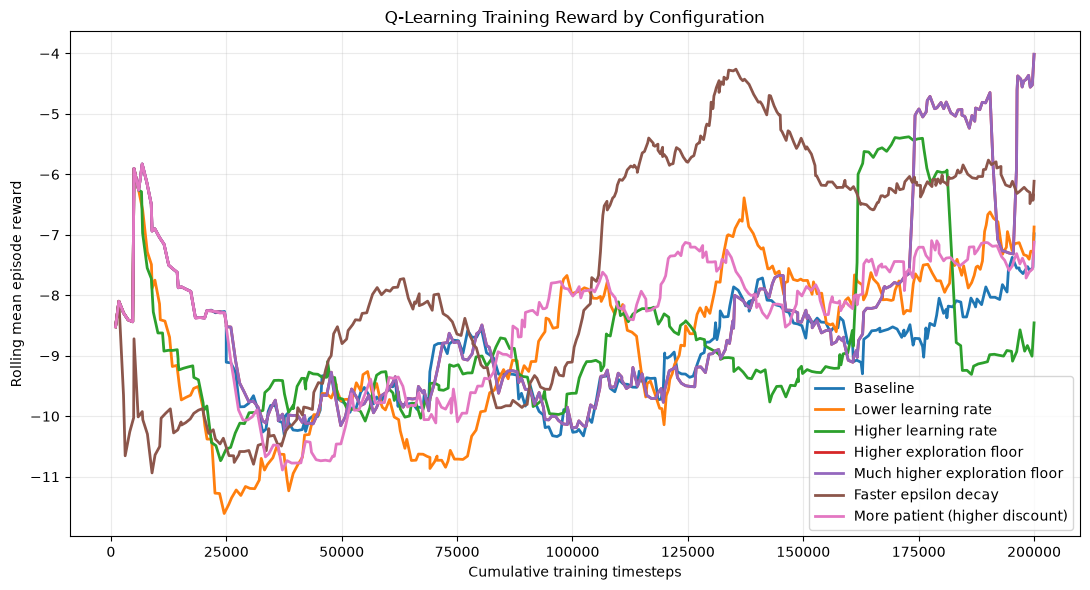

In [36]:
plt.figure(figsize=(11, 6))
plotted_training_runs = 0

for experiment in EXPERIMENTS_TO_RUN:
    monitor_path = RESULTS_DIRECTORY / f"{experiment['name']}_monitor.csv"

    if not monitor_path.exists():
        print("Training log not found:", monitor_path.name)
        continue

    # Check what is inside the CSV
    monitor_df = pd.read_csv(monitor_path, comment="#")

    print(f"\n{monitor_path.name}")
    print("Columns found:", monitor_df.columns.tolist())

    # Remove empty rows
    monitor_df = monitor_df.dropna(how="all")

    # Make sure required columns exist
    required_columns = ["r", "l"]

    missing_columns = [
        column for column in required_columns
        if column not in monitor_df.columns
    ]

    if missing_columns:
        print(
            f"Skipping {monitor_path.name}. "
            f"Missing columns: {missing_columns}"
        )
        continue

    if monitor_df.empty:
        print(f"Skipping empty file: {monitor_path.name}")
        continue

    # Convert columns to numeric
    monitor_df["r"] = pd.to_numeric(
        monitor_df["r"],
        errors="coerce"
    )

    monitor_df["l"] = pd.to_numeric(
        monitor_df["l"],
        errors="coerce"
    )

    # Remove invalid rows
    monitor_df = monitor_df.dropna(
        subset=["r", "l"]
    )

    if monitor_df.empty:
        print(f"No valid training data in: {monitor_path.name}")
        continue

    # Calculate cumulative timesteps
    monitor_df["cumulative_timesteps"] = (
        monitor_df["l"].cumsum()
    )

    rolling_window = min(
        50,
        max(5, len(monitor_df) // 10)
    )

    monitor_df["rolling_reward"] = (
        monitor_df["r"]
        .rolling(
            rolling_window,
            min_periods=1
        )
        .mean()
    )

    plt.plot(
        monitor_df["cumulative_timesteps"],
        monitor_df["rolling_reward"],
        linewidth=2,
        label=experiment["label"],
    )

    plotted_training_runs += 1


if plotted_training_runs == 0:
    plt.close()
    raise FileNotFoundError(
        "No valid monitor CSV files are available. "
        "Run the training queue first."
    )

plt.title("Q-Learning Training Reward by Configuration")
plt.xlabel("Cumulative training timesteps")
plt.ylabel("Rolling mean episode reward")
plt.grid(alpha=0.25)
plt.legend()

save_figure("training_reward_comparison.png")

### 10.2 Random baseline versus Q-learning metrics

The next figure uses three panels for mean reward, mean apples, and completion rate because these measures have different scales. Bar labels expose exact values, while a fixed completion-rate scale from zero to at least one prevents visual exaggeration. This is the main high-level comparison between untrained and learned behavior.

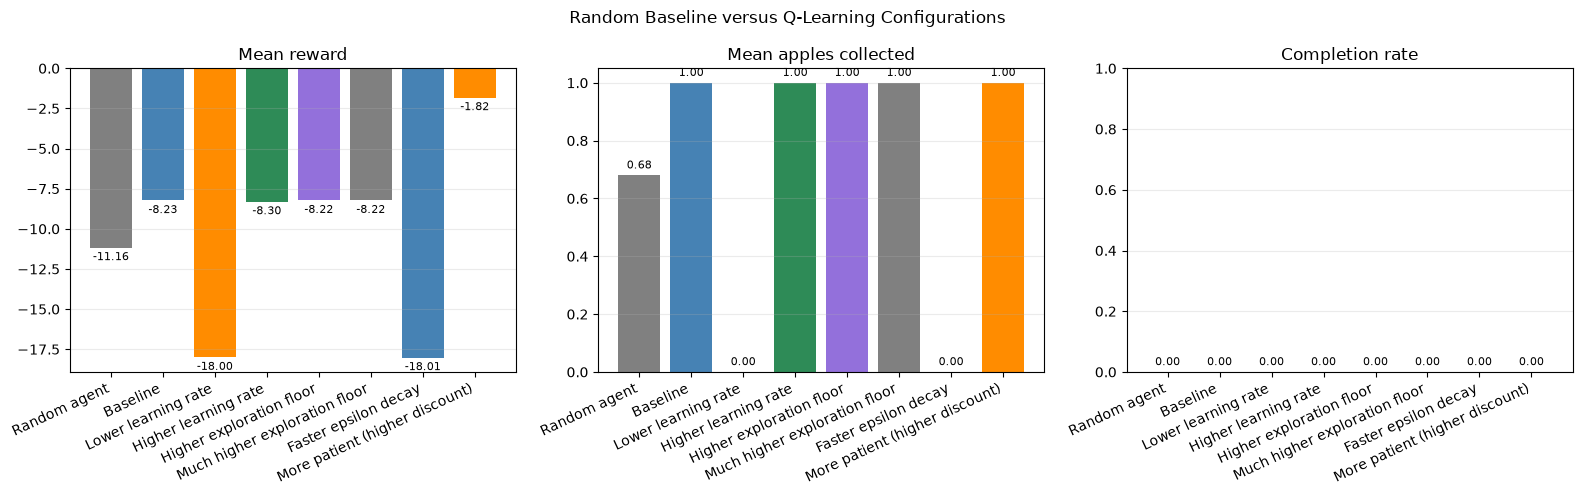

In [37]:
plot_comparison_df = comparison_df.set_index("label")
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metrics = [
    ("mean_reward", "Mean reward"),
    ("mean_apples", "Mean apples collected"),
    ("completion_rate", "Completion rate"),
]
colors = ["gray", "steelblue", "darkorange", "seagreen", "mediumpurple"]

for axis, (column, label) in zip(axes, metrics):
    values = plot_comparison_df[column]
    bars = axis.bar(range(len(values)), values, color=colors[: len(values)])
    axis.set_title(label)
    axis.set_xticks(range(len(values)), plot_comparison_df.index, rotation=25, ha="right")
    axis.grid(axis="y", alpha=0.25)
    axis.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
    if column == "completion_rate":
        axis.set_ylim(0, max(1.0, values.max() * 1.15))

fig.suptitle("Random Baseline versus Q-Learning Configurations")
save_figure("all_policy_metric_comparison.png")

### 10.3 Terminal-outcome diagnosis

The next cell combines random and Q-learning terminal reasons, converts counts to within-policy proportions, and compares success, enemy collision, fall, and timeout rates. The graph explains *how* policies end episodes, which is more diagnostic than reward alone—for example, it separates failure caused by unsafe movement from failure caused by inaction.

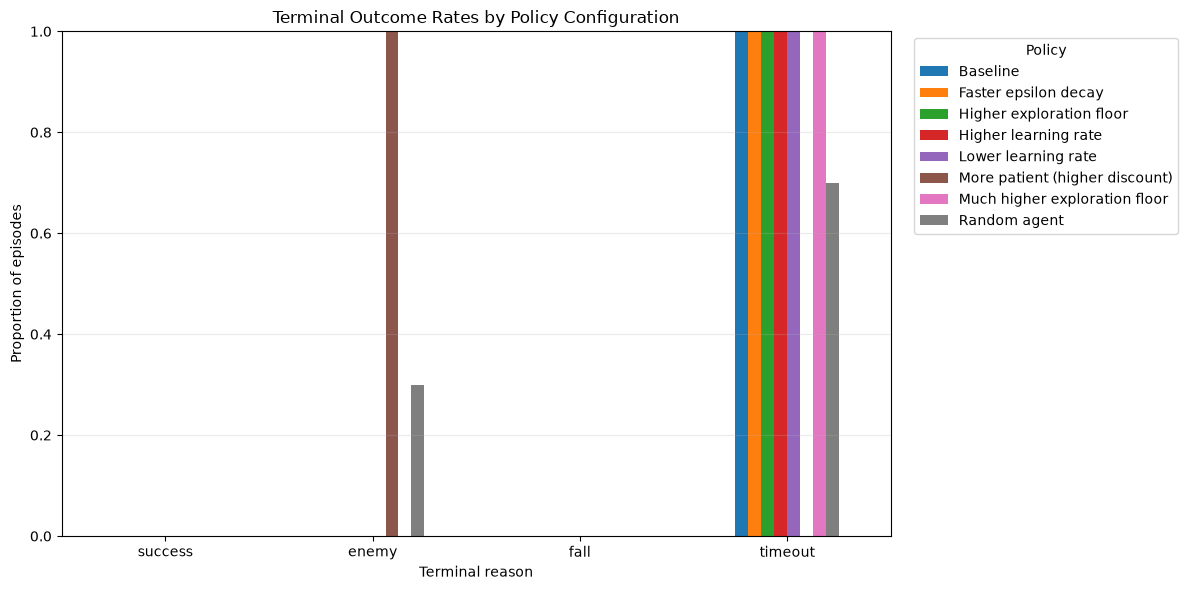

In [38]:
random_outcomes = random_results_df[["reason"]].copy()
random_outcomes["label"] = "Random agent"
q_outcomes = all_evaluation_df[["reason", "label"]].copy()
all_outcomes = pd.concat([random_outcomes, q_outcomes], ignore_index=True)

outcome_order = ["success", "enemy", "fall", "timeout"]
outcome_comparison = pd.crosstab(
    all_outcomes["reason"],
    all_outcomes["label"],
    normalize="columns",
).reindex(outcome_order).fillna(0.0)

outcome_comparison.plot(kind="bar", figsize=(12, 6))
plt.title("Terminal Outcome Rates by Policy Configuration")
plt.xlabel("Terminal reason")
plt.ylabel("Proportion of episodes")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.legend(title="Policy", bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure("all_terminal_outcomes.png")

### 10.4 Episode-level evaluation consistency

The next two-panel line plot shows deterministic reward and apples for every evaluation episode and configuration. Its purpose is to expose variation, repeated identical behavior, and isolated successes that an aggregate mean could hide. Empty configuration subsets are ignored.

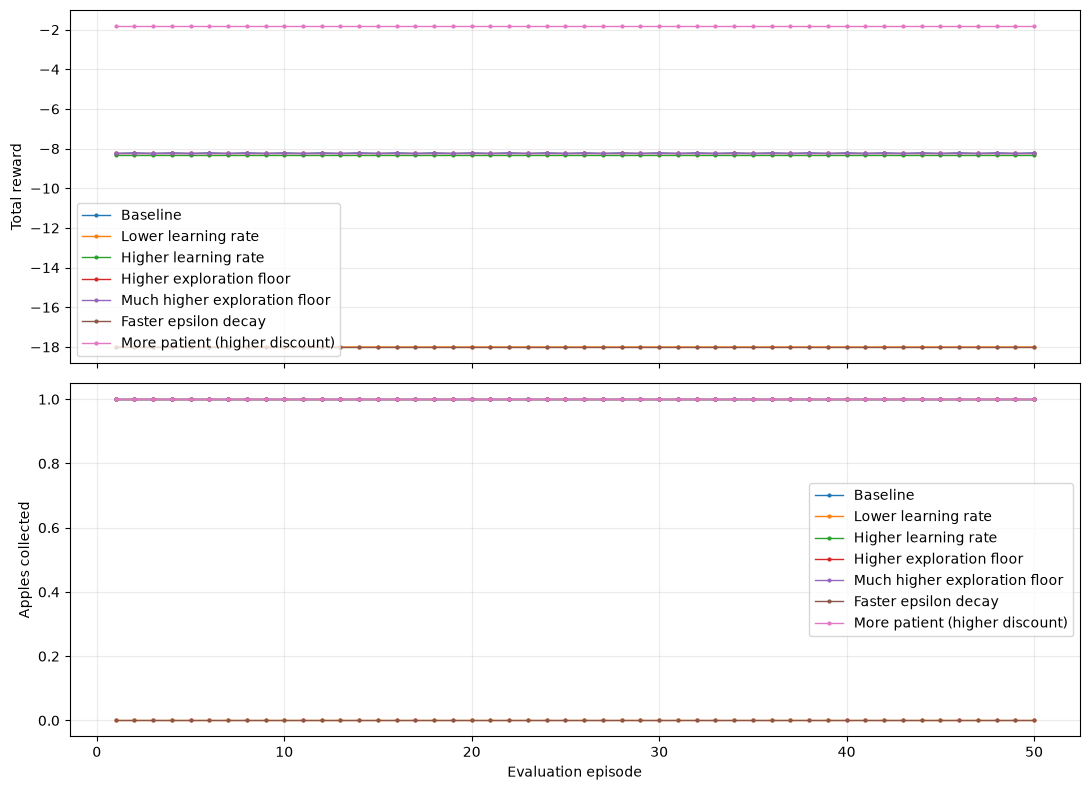

In [39]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

for experiment in EXPERIMENTS_TO_RUN:
    subset = all_evaluation_df[all_evaluation_df["name"] == experiment["name"]]
    if subset.empty:
        continue
    axes[0].plot(
        subset["episode"],
        subset["reward"],
        marker="o",
        markersize=2,
        linewidth=1,
        label=experiment["label"],
    )
    axes[1].plot(
        subset["episode"],
        subset["apples_collected"],
        marker="o",
        markersize=2,
        linewidth=1,
        label=experiment["label"],
    )

axes[0].set_ylabel("Total reward")
axes[0].grid(alpha=0.25)
axes[0].legend()
axes[1].set_xlabel("Evaluation episode")
axes[1].set_ylabel("Apples collected")
axes[1].grid(alpha=0.25)
axes[1].legend()
save_figure("all_evaluation_consistency.png")

### 10.5 Apples-collected distribution

The histogram counts episodes ending with zero, one, or two apples for each configuration. Integer-centered bins avoid splitting an apple count across bars. This plot directly tests the common failure pattern in which the lower apple is collected but the upper apple and route waypoint are not mastered.

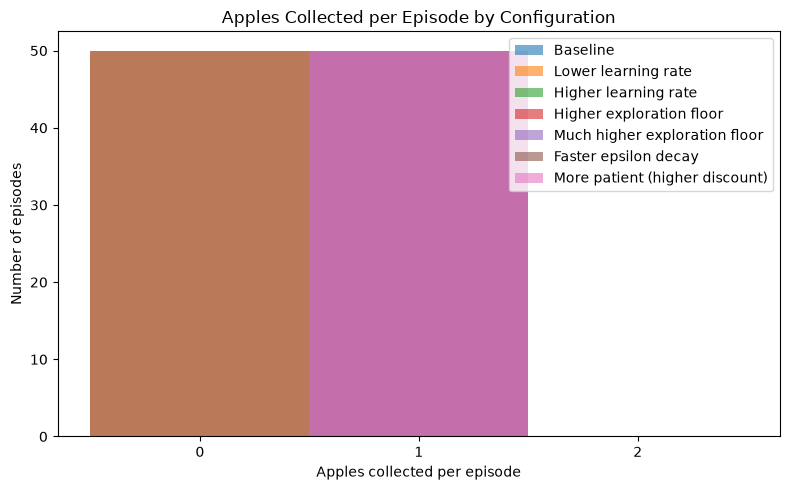

In [40]:
fig, ax = plt.subplots(figsize=(8, 5))
for experiment in EXPERIMENTS_TO_RUN:
    subset = all_evaluation_df[all_evaluation_df["name"] == experiment["name"]]
    # Bin edges are centered on 0, 1, 2 so each integer apple count gets its
    # own bar instead of being split across bin boundaries.
    ax.hist(
        subset["apples_collected"],
        bins=[-0.5, 0.5, 1.5, 2.5],
        alpha=0.6,
        label=experiment["label"],
    )
ax.set_xticks([0, 1, 2])
ax.set_xlabel("Apples collected per episode")
ax.set_ylabel("Number of episodes")
ax.set_title("Apples Collected per Episode by Configuration")
ax.legend()
save_figure("apples_collected_histogram.png")

## 11. Automatic result checks and model recommendation

The next cell prints cautious, task-oriented interpretations for every deterministic summary. It flags zero completion, zero reward variation, and improvements over the random control. It then recommends a configuration by completion rate first, mean apples second, and mean reward third. This ordering aligns model selection with the actual task rather than with shaped reward alone.

In [41]:
for _, result in experiment_summary_df.iterrows():
    print(f"\n{result['label']}:")
    if result["completion_rate"] == 0:
        print("• No successful completion; do not claim the task was solved.")
    else:
        print(f"• Completion rate: {result['completion_rate']:.1%}")
    if result["reward_std"] == 0:
        print("• Identical deterministic rewards; multiple training seeds are recommended.")
    if result["mean_reward"] > random_summary["mean_reward"]:
        print("• Mean reward improved relative to the random policy.")
    if result["mean_apples"] > random_summary["mean_apples"]:
        print("• More apples were collected than by the random policy.")

# Select lexicographically by task success, then partial progress, then reward.
# This prevents a short failing policy from winning merely because it avoids
# accumulating step penalties.
best_result = experiment_summary_df.sort_values(
    ["completion_rate", "mean_apples", "mean_reward"],
    ascending=False,
).iloc[0]
print(
    f"\nRecommended configuration: {best_result['label']} — "
    f"completion={best_result['completion_rate']:.1%}, "
    f"apples={best_result['mean_apples']:.2f}, "
    f"reward={best_result['mean_reward']:.3f}"
)


Baseline:
• No successful completion; do not claim the task was solved.
• Mean reward improved relative to the random policy.
• More apples were collected than by the random policy.

Lower learning rate:
• No successful completion; do not claim the task was solved.

Higher learning rate:
• No successful completion; do not claim the task was solved.
• Mean reward improved relative to the random policy.
• More apples were collected than by the random policy.

Higher exploration floor:
• No successful completion; do not claim the task was solved.
• Mean reward improved relative to the random policy.
• More apples were collected than by the random policy.

Much higher exploration floor:
• No successful completion; do not claim the task was solved.
• Mean reward improved relative to the random policy.
• More apples were collected than by the random policy.

Faster epsilon decay:
• No successful completion; do not claim the task was solved.
• Identical deterministic rewards; multiple traini

## 12. Best-policy trajectory heatmap

The next cell loads the recommended checkpoint and collects every player position from 30 stochastic (epsilon-greedy) episodes. A 2D visit-density map reveals which parts of the 1,280×720 level the policy explores. Godot's downward-positive y-axis is inverted for intuitive display. Sparse visits near the central-platform and upper-apple route provide spatial evidence for why a policy may stop after one apple — for tabular Q-learning specifically, sparse visits can also mean the corresponding discretized states were rarely or never reached during training, so their Q-values never moved away from zero.

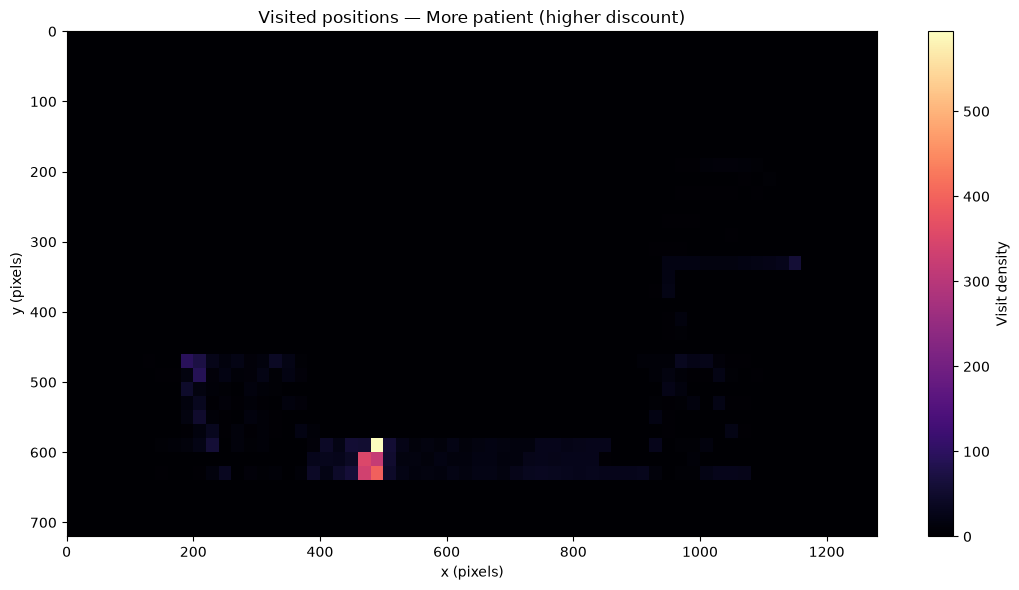

In [42]:
trajectory_env = AS4GodotEnv(headless=HEADLESS)
try:
    best_name = best_result["name"]  # from the automatic result checks above
    best_agent = QLearningAgent.load(MODELS_DIRECTORY / f"as4_qlearning_{best_name}_best")

    # run_episodes already returns per-step (x, y) positions as its second
    # value, so reuse it directly instead of a separate trajectory-collection
    # function. deterministic=False so the plot reflects the full range of
    # behavior the policy can produce, not just one fixed path.
    _, trajectory_df = run_episodes(
        trajectory_env, episodes=30, model=best_agent, deterministic=False
    )
finally:
    trajectory_env.close()

trajectory_df.to_csv(RESULTS_DIRECTORY / f"{best_name}_trajectories.csv", index=False)

plt.figure(figsize=(11, 6))
plt.hist2d(
    trajectory_df["x"], trajectory_df["y"],
    bins=[64, 36],
    range=[[0, 1280], [0, 720]],
    cmap="magma",
)
plt.gca().invert_yaxis()  # Godot's y-axis increases downward
plt.colorbar(label="Visit density")
plt.title(f"Visited positions — {best_result['label']}")
plt.xlabel("x (pixels)")
plt.ylabel("y (pixels)")
save_figure(f"{best_name}_position_heatmap.png")

## 13. Interpretation criteria and first-seed limitation

The initial comparison uses training seed `123`. Interpret configurations in this priority order:

1. Completion rate
2. Mean apples collected
3. Mean evaluation reward
4. Reward standard deviation
5. Mean episode length and terminal-outcome proportions

The notebook computes `best_result` automatically, so report values should be taken from the generated summaries rather than manually entered placeholders. The seven configurations form a controlled one-factor-at-a-time study, but one training seed cannot show whether an apparent advantage is robust to the random-number-generator state that drives both the epsilon-greedy exploration schedule and any never-visited-state tie-breaking. Sections 14.1–14.4 therefore repeat the experiment using three reproducibly generated additional seeds and aggregate across four seeds in total.

Training time depends strongly on hardware and rendering. Use the saved `training_seconds` metadata from the current runs instead of retaining an old wall-clock estimate.

## 14. Multi-seed validation

### 14.1 Define additional seeds

The next cell uses a fixed NumPy meta-seed (`1000`) to generate three additional integer seeds. Combining them with the original seed 123 produces four seeds per configuration. A reproducible seed matrix makes repeated grading or reruns select the same experimental conditions while still measuring sensitivity to the agent's independent random-number-generator state.

In [43]:
# Generate three additional seeds reproducibly. A fixed meta-seed (1000) means
# this exact list is identical every time the notebook is re-run.
SEED_META_RNG = np.random.default_rng(1000)
ADDITIONAL_SEEDS = [int(s) for s in SEED_META_RNG.integers(0, 1000, size=3)]
ALL_SEEDS = [SEED] + ADDITIONAL_SEEDS

print("Original training seed:", SEED)
print("Additional seeds:", ADDITIONAL_SEEDS)
print("Full seed matrix:", ALL_SEEDS)
print(f"Total training runs: {len(EXPERIMENTS_TO_RUN)} configs x {len(ALL_SEEDS)} seeds "
      f"= {len(EXPERIMENTS_TO_RUN) * len(ALL_SEEDS)} "
      f"({len(EXPERIMENTS_TO_RUN)} already trained, "
      f"{len(EXPERIMENTS_TO_RUN) * len(ADDITIONAL_SEEDS)} new)")

Original training seed: 123
Additional seeds: [203, 521, 848]
Full seed matrix: [123, 203, 521, 848]
Total training runs: 7 configs x 4 seeds = 28 (7 already trained, 21 new)


### 14.2 Train every configuration on the additional seeds

The next cell performs 21 new full training runs: seven configurations × three additional seeds. Before each run it reseeds NumPy through the agent's own generator, launches a fresh monitored Godot environment, trains directly for the common 200,000-step budget, and saves the Q-table and metadata using a seed-specific filename.

Completed seed-specific models can be skipped when resume mode is enabled. Unlike the initial queue, this loop does not run a separate smoke stage or save periodic checkpoints; its purpose is independent-seed replication of the final configurations.

In [44]:
import gc

seed_matrix_metadata = []

for seed in ADDITIONAL_SEEDS:
    for queue_position, experiment in enumerate(EXPERIMENTS_TO_RUN, start=1):
        name = experiment["name"]
        label = experiment["label"]
        run_name = f"{name}_seed{seed}"
        model_path = MODELS_DIRECTORY / f"as4_qlearning_{run_name}"
        model_file_path = model_path.with_suffix(".pkl")
        monitor_path = RESULTS_DIRECTORY / f"{run_name}_monitor.csv"
        metadata_path = RESULTS_DIRECTORY / f"{run_name}_training_metadata.csv"
        resolved_config = {**BASE_Q_CONFIG, **experiment["overrides"]}

        print(f"\n[seed {seed}, {queue_position}/{len(EXPERIMENTS_TO_RUN)}] {label}")

        if SKIP_COMPLETED_MODELS and model_file_path.exists():
            print("Completed model already exists; skipping training:", model_file_path)
            if metadata_path.exists():
                seed_matrix_metadata.append(pd.read_csv(metadata_path).iloc[0].to_dict())
            continue

        training_env = AS4GodotEnv(headless=HEADLESS)
        monitor = QLearningMonitor(
            monitor_path,
            info_keywords=("reason", "apples_collected", "total_reward"),
        )
        training_start = time.perf_counter()

        try:
            # Reseeding here (rather than reusing SEED's generator state) makes
            # each of the 21 new runs genuinely independent, matching the PPO
            # notebook's per-run set_random_seed(seed) call.
            agent = QLearningAgent(
                bins_per_dimension=BINS_PER_DIMENSION,
                low=OBSERVATION_LOW,
                high=OBSERVATION_HIGH,
                n_actions=N_ACTIONS,
                seed=seed,
                **resolved_config,
            )
            train_q_learning(
                agent,
                training_env,
                total_timesteps=TARGET_TOTAL_TIMESTEPS,
                monitor=monitor,
            )
            agent.save(model_path)

            record = {
                "name": name,
                "label": label,
                "seed": seed,
                "timesteps": agent.num_timesteps,
                "states_visited": len(agent.q_table),
                "final_epsilon": agent.epsilon_current,
                "training_seconds": time.perf_counter() - training_start,
                **resolved_config,
            }
            pd.DataFrame([record]).to_csv(metadata_path, index=False)
            seed_matrix_metadata.append(record)
            print("Saved completed model:", model_file_path)
        finally:
            training_env.close()
            monitor.close()
            if "agent" in locals():
                del agent
            gc.collect()

if seed_matrix_metadata:
    seed_matrix_metadata_df = pd.DataFrame(seed_matrix_metadata)
    seed_matrix_metadata_df.to_csv(RESULTS_DIRECTORY / "seed_matrix_training_metadata.csv", index=False)
    display(seed_matrix_metadata_df)

print("\nMulti-seed training matrix finished.")


[seed 203, 1/7] Baseline
Completed model already exists; skipping training: D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\models\as4_qlearning_baseline_seed203.pkl

[seed 203, 2/7] Lower learning rate
Completed model already exists; skipping training: D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\models\as4_qlearning_low_alpha_seed203.pkl

[seed 203, 3/7] Higher learning rate
Completed model already exists; skipping training: D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\models\as4_qlearning_high_alpha_seed203.pkl

[seed 203, 4/7] Higher exploration floor
Completed model already exists; skipping training: D:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\GodotGameEngineScene\as-4\models\as4_qlearning_high_exploration_seed203.pkl

[seed 203, 5/7] Much higher exploration floor
Completed model already exists; skipping training: D:\GitHub\UCCD2063-A

,name,label,seed,timesteps,states_visited,final_epsilon,training_seconds,alpha,gamma,epsilon_start,epsilon_min,epsilon_decay
0,baseline,Baseline,203,200000,645,0.874123,397.400177,0.10,0.990,1.0,0.05,0.9995
1,low_alpha,Lower learning rate,203,200000,595,0.870633,377.777353,0.03,0.990,1.0,0.05,0.9995
2,high_alpha,Higher learning rate,203,200000,610,0.878946,377.107373,0.30,0.990,1.0,0.05,0.9995
3,high_exploration,Higher exploration floor,203,200000,535,0.873686,384.355815,0.10,0.990,1.0,0.15,0.9995
4,very_high_exploration,Much higher exploration floor,203,200000,645,0.874123,363.732284,0.10,0.990,1.0,0.30,0.9995
5,fast_epsilon_decay,Faster epsilon decay,203,200000,644,0.713075,388.438466,0.10,0.990,1.0,0.05,0.9990
6,high_gamma,More patient (higher discount),203,200000,590,0.868459,378.190472,0.10,0.995,1.0,0.05,0.9995
7,baseline,Baseline,521,200000,672,0.878067,375.295842,0.10,0.990,1.0,0.05,0.9995
8,low_alpha,Lower learning rate,521,200000,537,0.874998,396.698963,0.03,0.990,1.0,0.05,0.9995
9,high_alpha,Higher learning rate,521,200000,562,0.882028,381.241829,0.30,0.990,1.0,0.05,0.9995



Multi-seed training matrix finished.


### 14.3 Evaluate every configuration–seed pair

The next cell discovers the original and seed-specific final Q-table files, runs the common 50-episode deterministic protocol for each available pair, and saves one summary row per configuration and seed. Missing files are reported and skipped so partial matrices can still be inspected.

For seed 123 this stage loads the final `as4_qlearning_<name>.pkl` model, whereas Section 8 prefers the checkpoint-screened `*_best.pkl`. Therefore the seed-matrix comparison is a final-model comparison and should not be mixed directly with Section 8's best-checkpoint statistics.

In [45]:
seed_matrix_results = []

for seed in ALL_SEEDS:
    for experiment in EXPERIMENTS_TO_RUN:
        name = experiment["name"]
        label = experiment["label"]
        run_name = name if seed == SEED else f"{name}_seed{seed}"
        model_file_path = MODELS_DIRECTORY / f"as4_qlearning_{run_name}.pkl"

        if not model_file_path.exists():
            print(f"Skipping evaluation; model not found: {model_file_path}")
            continue

        print(f"Evaluating {label} (seed {seed})")
        agent = QLearningAgent.load(model_file_path.with_suffix(""))
        evaluation_env = AS4GodotEnv(headless=HEADLESS)

        try:
            result_df, _ = run_episodes(
                evaluation_env,
                FINAL_EVALUATION_EPISODES,
                model=agent,
                deterministic=True,
            )
        finally:
            evaluation_env.close()

        summary = summarize_results(result_df)
        summary["name"] = name
        summary["label"] = label
        summary["seed"] = seed
        seed_matrix_results.append(summary)

        del agent
        gc.collect()

seed_matrix_results_df = pd.DataFrame(seed_matrix_results)
seed_matrix_results_df.to_csv(RESULTS_DIRECTORY / "seed_matrix_evaluation_results.csv", index=False)
display(seed_matrix_results_df[
    ["label", "seed", "mean_reward", "mean_apples", "completion_rate"]
].round(3))

Evaluating Baseline (seed 123)
Evaluating Lower learning rate (seed 123)
Evaluating Higher learning rate (seed 123)
Evaluating Higher exploration floor (seed 123)
Evaluating Much higher exploration floor (seed 123)
Evaluating Faster epsilon decay (seed 123)
Evaluating More patient (higher discount) (seed 123)
Evaluating Baseline (seed 203)
Evaluating Lower learning rate (seed 203)
Evaluating Higher learning rate (seed 203)
Evaluating Higher exploration floor (seed 203)
Evaluating Much higher exploration floor (seed 203)
Evaluating Faster epsilon decay (seed 203)
Evaluating More patient (higher discount) (seed 203)
Evaluating Baseline (seed 521)
Evaluating Lower learning rate (seed 521)
Evaluating Higher learning rate (seed 521)
Evaluating Higher exploration floor (seed 521)
Evaluating Much higher exploration floor (seed 521)
Evaluating Faster epsilon decay (seed 521)
Evaluating More patient (higher discount) (seed 521)
Evaluating Baseline (seed 848)
Evaluating Lower learning rate (seed

,label,seed,mean_reward,mean_apples,completion_rate
0,Baseline,123,-8.232,1.0,0.0
1,Lower learning rate,123,-18.014,0.0,0.0
2,Higher learning rate,123,-8.304,1.0,0.0
3,Higher exploration floor,123,-8.224,1.0,0.0
4,Much higher exploration floor,123,-8.224,1.0,0.0
5,Faster epsilon decay,123,-8.539,1.0,0.0
6,More patient (higher discount),123,-1.820,1.0,0.0
7,Baseline,203,-1.205,1.0,0.0
8,Lower learning rate,203,-18.014,0.0,0.0
9,Higher learning rate,203,-8.621,1.0,0.0


### 14.3 Aggregate mean ± standard deviation across seeds

The next cell groups seed-level summaries by configuration and calculates the mean and sample standard deviation of completion rate, apples, and reward, plus the number of seeds actually evaluated. It exports `seed_matrix_summary.csv` and plots mean completion with seed-to-seed error bars. With a complete run, each estimate is based on four seeds; always verify `seeds_evaluated` before citing the result.

,name,label,completion_rate_mean,completion_rate_std,mean_apples_mean,mean_apples_std,mean_reward_mean,mean_reward_std,seeds_evaluated
0,baseline,Baseline,0.0,0.0,1.0,0.0,-6.560,3.573,4
1,fast_epsilon_decay,Faster epsilon decay,0.0,0.0,1.0,0.0,-4.807,4.308,4
2,high_alpha,Higher learning rate,0.0,0.0,1.0,0.0,-8.519,0.147,4
3,high_exploration,Higher exploration floor,0.0,0.0,1.0,0.0,-8.301,0.140,4
4,high_gamma,More patient (higher discount),0.0,0.0,1.0,0.0,-3.086,3.501,4
5,low_alpha,Lower learning rate,0.0,0.0,0.0,0.0,-18.011,0.006,4
6,very_high_exploration,Much higher exploration floor,0.0,0.0,1.0,0.0,-6.496,3.527,4


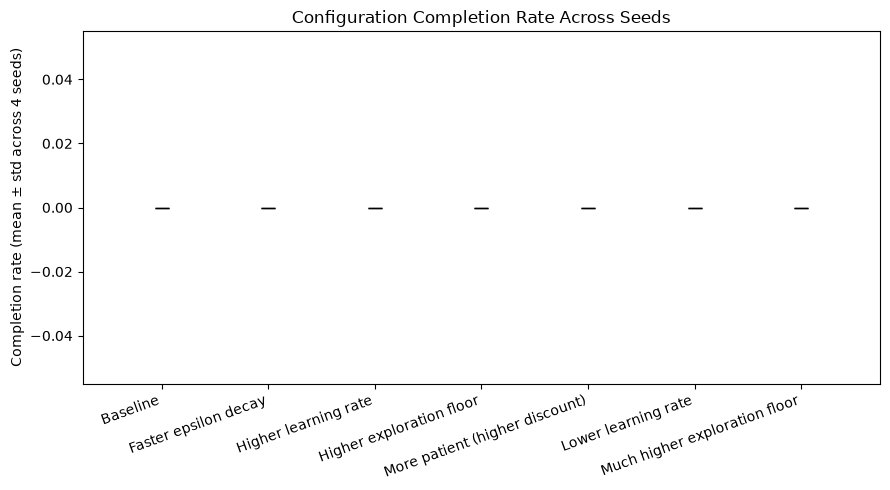

In [46]:
seed_matrix_summary_df = (
    seed_matrix_results_df
    .groupby(["name", "label"])
    .agg(
        completion_rate_mean=("completion_rate", "mean"),
        completion_rate_std=("completion_rate", "std"),
        mean_apples_mean=("mean_apples", "mean"),
        mean_apples_std=("mean_apples", "std"),
        mean_reward_mean=("mean_reward", "mean"),
        mean_reward_std=("mean_reward", "std"),
        seeds_evaluated=("seed", "count"),
    )
    .reset_index()
)
seed_matrix_summary_df.to_csv(RESULTS_DIRECTORY / "seed_matrix_summary.csv", index=False)
display(seed_matrix_summary_df.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
x_positions = np.arange(len(seed_matrix_summary_df))
ax.bar(
    x_positions,
    seed_matrix_summary_df["completion_rate_mean"],
    yerr=seed_matrix_summary_df["completion_rate_std"],
    capsize=5,
)
ax.set_xticks(x_positions)
ax.set_xticklabels(seed_matrix_summary_df["label"], rotation=20, ha="right")
ax.set_ylabel("Completion rate (mean ± std across 4 seeds)")
ax.set_title("Configuration Completion Rate Across Seeds")
save_figure("seed_matrix_completion_rate.png")

## 15. Assignment report material checklist

### Methodology evidence

- Environment screenshot and task description
- Observation, action, reward, termination, and truncation definitions
- State discretization scheme (bins per observation) and its trade-offs
- Python–WebSocket–Godot interaction explanation
- Tabular Q-learning update rule and epsilon-greedy exploration explanation
- Seven-configuration controlled hyperparameter table
- Training budget, software versions, and seed protocol
- Checkpoint-screening and deterministic/stochastic evaluation procedures

### Results evidence

- Training learning-curve comparison
- Random-versus-Q-learning metric table and graph
- Terminal-outcome proportions
- Episode-level consistency and apples distribution
- Best-policy trajectory heatmap
- Four-seed mean ± standard deviation table when the matrix is complete
- Raw CSV evidence, measured training times, and Q-table size (`states_visited`) per configuration

### Discussion evidence

- Select the best policy using completion and apples before reward
- Explain dominant failure modes and route coverage
- Discuss deterministic (greedy) versus stochastic (epsilon-greedy) behavior
- Relate each result to the single hyperparameter changed
- Discuss how the discretization resolution may limit what tabular Q-learning can represent compared to PPO's neural-network policy
- State missing runs, zero completion, or incomplete seed matrices honestly

Console screenshots are optional appendix material; they do not replace saved metrics, plots, and interpretation.

## 16. Operations review and redundancy audit

The code review found the following redundant or duplicated operations, carried over and adjusted from the PPO notebook's own audit:

1. **Unused configuration path:** `CONFIG_DIRECTORY` is defined but never read; there is currently no active `q_configs/` workflow, since configurations are defined directly in code (Section 6).
2. **Duplicate random-action seeding:** `random_env.action_space.seed(SEED)` is repeated by the first `run_episodes(..., seed=SEED)` reset because `AS4GodotEnv.reset` also seeds the action space.
3. **Repeated import:** `import gc` appears before both training loops. Python caches imports, so the second import is harmless but unnecessary.
4. **Unused checkpoint dictionary:** `best_checkpoint_paths` is populated during screening but never read later; later cells reconstruct model paths from filenames.
5. **Duplicated training-loop structure:** the initial and multi-seed queues repeat agent/environment/metadata setup. Their behavior is not identical (smoke stage, periodic checkpoints, and checkpoint-resume only exist in the initial queue), so both loops are meaningful, but a shared training helper would reduce maintenance drift.
6. **Repeated environment validation:** `check_env` appears in both this notebook and `test_environment.py`. Keeping both is useful for independent execution, but running both every time duplicates the basic interface check.
7. **Unused Godot signal:** `main.gd` emits `step_finished`, but the current bridge directly awaits `agent_step` and no project code connects to the signal. The signal emission is therefore presently redundant.

Expensive operations that are **not inherently redundant** include deterministic plus stochastic evaluation, periodic checkpoint screening, and multi-seed retraining: each answers a different reliability question. They can be reduced for development runs, but removing them from final experiments would weaken the evidence.

### Non-redundancy issues carried over from the PPO notebook

- `test_environment.py` still comments and asserts an earlier −30 terminal penalty and +15 apple reward. The active `main.gd` values are −10 and +5, so enemy/fall assertions can fail even when the current environment is correct. This is unrelated to the choice of algorithm and was not introduced by this conversion.
- Section 8 evaluates checkpoint-selected best Q-tables, while the multi-seed matrix (Section 14) evaluates final Q-tables. Use one checkpoint policy consistently if those result sets must be compared directly.
- `STATE_SPACE_SIZE` (Section 2.2) is a theoretical upper bound; report writing should cite `states_visited` from the training metadata for the actual Q-table size of a given run, since most discretized states are never reached in 200,000 steps.